<a href="https://colab.research.google.com/github/l0ry01/Laspy/blob/main/Laspy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Analýza LiDARových dat pomocí knihovny Laspy**

Cílem projektu je představit možnosti knihovny Laspy při zpracování
LiDARových mračen bodů.

Hlavní cíl je vytvoření CHM (Canopy Height Model) z Lidarového mračna
1.   Načtení knihoven a dat
2.   **DTM** - filtrace ground bodů
1.   **DSM** - filtrace vegetace
2.   **CHM** - Canopy Height Model

**K čemu slouží Laspy?**

**Laspy** je Python knihovna určená pro práci s daty Lidarových mračen ve formátech LAS a LAZ.

Umožňuje především:

Načítání a ukládání souborů LAS a LAZ.

*   Načítání a ukládání souborů LAS a LAZ.
*   Přístup k jednotlivým bodům a jejich souřadnicím X, Y, Z
*   Práci s klasifikačními třídami bodů.
*   Přístup k metadatům souboru, například k souřadnicovému systému, počtu bodů nebo měřítku souřadnic.
*   Čtení dalších atributů bodů, například intenzity odrazu nebo počtu návratů

Sama o sobě ale knihovna **Laspy** neposkytuje komplexní nástroje pro prostorové analýzy, interpolace nebo vizualizaci.

V práci jsme využili další kniovny:
*   NumPy - Práce s číselnými poli, filtrování bodů, výpočty a statistické operace.
*   Pandas - Organizace výsledků do tabulek a výpočet statistik klasifikačních tříd a percentilů.
*   Matplotlib - Vizualizace mračna bodů, 3D zobrazení a vykreslení výsledných rastrů.
*   Pyinterp - Prostorová interpolace metodou IDW při tvorbě digitálního modelu terénu (DTM).
*   Rasterio - Ukládání výsledných modelů DTM, DSM a CHM do formátu GeoTIFF včetně prostorové reference.

**Jaké funkce Laspy jsme použili?**


*  ` laspy.read()` - Načtení souboru LAS/LAZ do Pythonu.
*   `data.points` - Přístup k záznamům jednotlivých bodů v mračnu.
*   `data.x, data.y, data.z` - Získání prostorových souřadnic jednotlivých bodů.
*   `data.classification` - Přístup ke klasifikačním třídám bodů.
*   `data.header` - Přístup k hlavičce souboru a jeho metadatům.
*   `data.header.parse_crs()` - Zjištění souřadnicového systému dat.



In [1]:
# nacteni knihoven
!pip install -q laspy lazrs

import laspy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib
!pip install pyinterp
import rasterio
from rasterio.transform import from_origin

from google.colab import files

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 12.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pyinterp]


**1. Načtení dat**

Bude nás zajímat počet bodů, souřadnicový systém a počet klasifikačních tříd

Všiměme si funkcí Laspy knihovny:


```
laspy.read
data.header.parse_crs()
data.classification
```



In [2]:
# Načtení dat
data = laspy.read("/content/kanary.laz")

# Zjištění počtu bodů v mračnu
print("Počet bodů:", len(data.points))

# Kontrola CRS
print("CRS:", data.header.parse_crs())

# Statistiky klasifikačních tříd
classes, counts = np.unique(data.classification, return_counts=True)

classification_stats = pd.DataFrame({
    "Klasifikace": classes,
    "Počet bodů": counts,
    "Podíl (%)": counts / len(data.points) * 100,
    "Min Z [m]": [
        data.z[data.classification == cls].min() for cls in classes
    ],
    "Max Z [m]": [
        data.z[data.classification == cls].max() for cls in classes
    ]
})

print("\nPočet zastoupených klasifikačních tříd:", len(classes))
display(classification_stats)

Počet bodů: 8468362
CRS: EPSG:25828

Počet zastoupených klasifikačních tříd: 8


,Klasifikace,Počet bodů,Podíl (%),Min Z [m],Max Z [m]
0,1,61537,0.726669,526.52,937.44
1,2,2424169,28.626185,526.31,940.07
2,3,918361,10.844612,526.40,947.54
3,4,406129,4.795839,529.47,941.73
4,5,393439,4.645987,542.29,952.85
5,6,57986,0.684737,558.89,820.83
6,7,128,0.001512,593.76,1031.29
7,12,4206613,49.674459,526.31,894.87


Podíváme se i na prostorové rozpětí mračna



```
data.x
data.y
data.z
```



In [3]:
# rozpeti datasetu

# Minimální a maximální souřadnice
print("Prostorový rozsah mračna:")

print(f"X: {data.x.min():.2f} – {data.x.max():.2f} m")
print(f"Y: {data.y.min():.2f} – {data.y.max():.2f} m")
print(f"Z: {data.z.min():.2f} – {data.z.max():.2f} m")

# Rozměry zájmového území
width = data.x.max() - data.x.min()
height = data.y.max() - data.y.min()
elevation = data.z.max() - data.z.min()

print("\nRozměry zájmového území:")
print(f"Šířka: {width:.2f} m")
print(f"Délka: {height:.2f} m")
print(f"Výškové rozpětí: {elevation:.2f} m")

Prostorový rozsah mračna:
X: 218000.00 – 219999.99 m
Y: 3170000.00 – 3171999.99 m
Z: 526.31 – 1031.29 m

Rozměry zájmového území:
Šířka: 1999.99 m
Délka: 1999.99 m
Výškové rozpětí: 504.98 m


**2.Ground Filtering**

CHM model se vypočítá jako DSM-DTM. Jako první si vytvoříme DTM z groundových bodů. Tedy nejnižích bodů mračna. Mračno je klasifikované a ground body obsahuje třída 2. Zkontrolujeme si i výšku groundových bodů.

Otázka za 2b: Jakou výšku by měly groundové body, kdybychom používali normalizované mračno?



In [4]:
## Ground filtering – extrakce terénních bodů

# Výběr terénních bodů (Ground = class 2)
ground_mask = data.classification == 2

# Vytvoření samostatného mračna terénních bodů
ground = data.points[ground_mask]

print("Počet terénních bodů:", len(ground))
print("Podíl terénních bodů: {:.2f} %".format(
    len(ground) / len(data.points) * 100
))

# výškové rozpětí vybraných bodů:
ground_z = ground.z

print("Minimální výška terénu:", round(ground_z.min(), 2), "m")
print("Maximální výška terénu:", round(ground_z.max(), 2), "m")

Počet terénních bodů: 2424169
Podíl terénních bodů: 28.63 %
Minimální výška terénu: 526.31 m
Maximální výška terénu: 940.07 m


Groundové body si zobrazíme, abychom věděli, zda jsou klasifikované správně.

Počet bodů ve výřezu: 9255
Počet Ground bodů: 5331


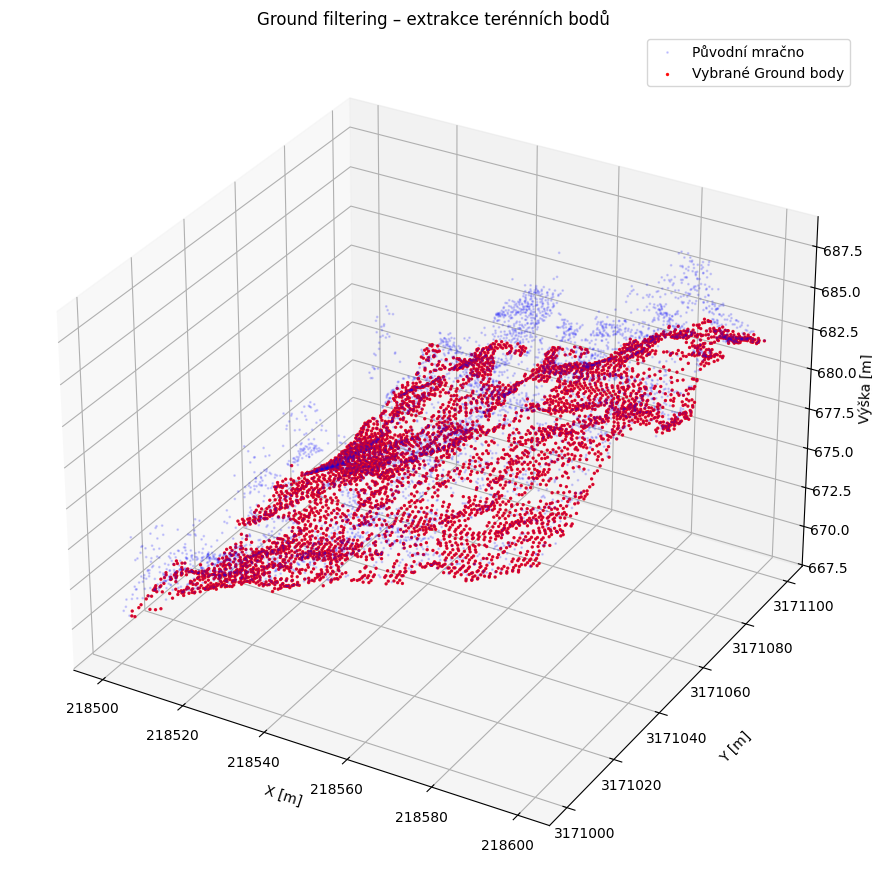

In [5]:
# 3D vizualizace/kontrola ground bodů - výřez

# Vymezení výřezu 100 × 100 m
xmin, xmax = 218500, 218600
ymin, ymax = 3171000, 3171100

area_mask = (
    (data.x >= xmin) & (data.x <= xmax) &
    (data.y >= ymin) & (data.y <= ymax)
)

# Výběr bodů z výřezu
area = data.points[area_mask]

# Rozdělení na Ground a ostatní body
area_ground = area[area.classification == 2]
area_other = area[area.classification != 2]

print("Počet bodů ve výřezu:", len(area))
print("Počet Ground bodů:", len(area_ground))
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

# Původní mračno – světle šedé body
ax.scatter(
    area.x, area.y, area.z,
    c="blue",
    s=1,
    alpha=0.15,
    label="Původní mračno"
)

# Vybrané Ground body – červeně
ax.scatter(
    area_ground.x, area_ground.y, area_ground.z,
    c="red",
    s=2,
    alpha=0.9,
    label="Vybrané Ground body"
)

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]",labelpad = 15)
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.set_zlabel("Výška [m]")
ax.set_title("Ground filtering – extrakce terénních bodů")
ax.legend()

plt.tight_layout()
plt.show()

**Tvorba DTM**

Z vybraných terénních bodů potřebujeme vytvořit výškový rastr. V mračnu se totiž mohou vyskytovat místa bez bodů, případně mezery na okrajích měřené oblasti.

Pro doplnění chybějících výškových hodnot použijeme **IDW interpolaci**.

Pro samotnou interpolaci jsme si připravili vlastní funkci v samostatném Python skriptu `idw.py`, kterou následně zavoláme v notebooku.

Výsledkem bude digitální model terénu (DTM) ve formě rastru s prostorovým rozlišením 2 × 2 m.

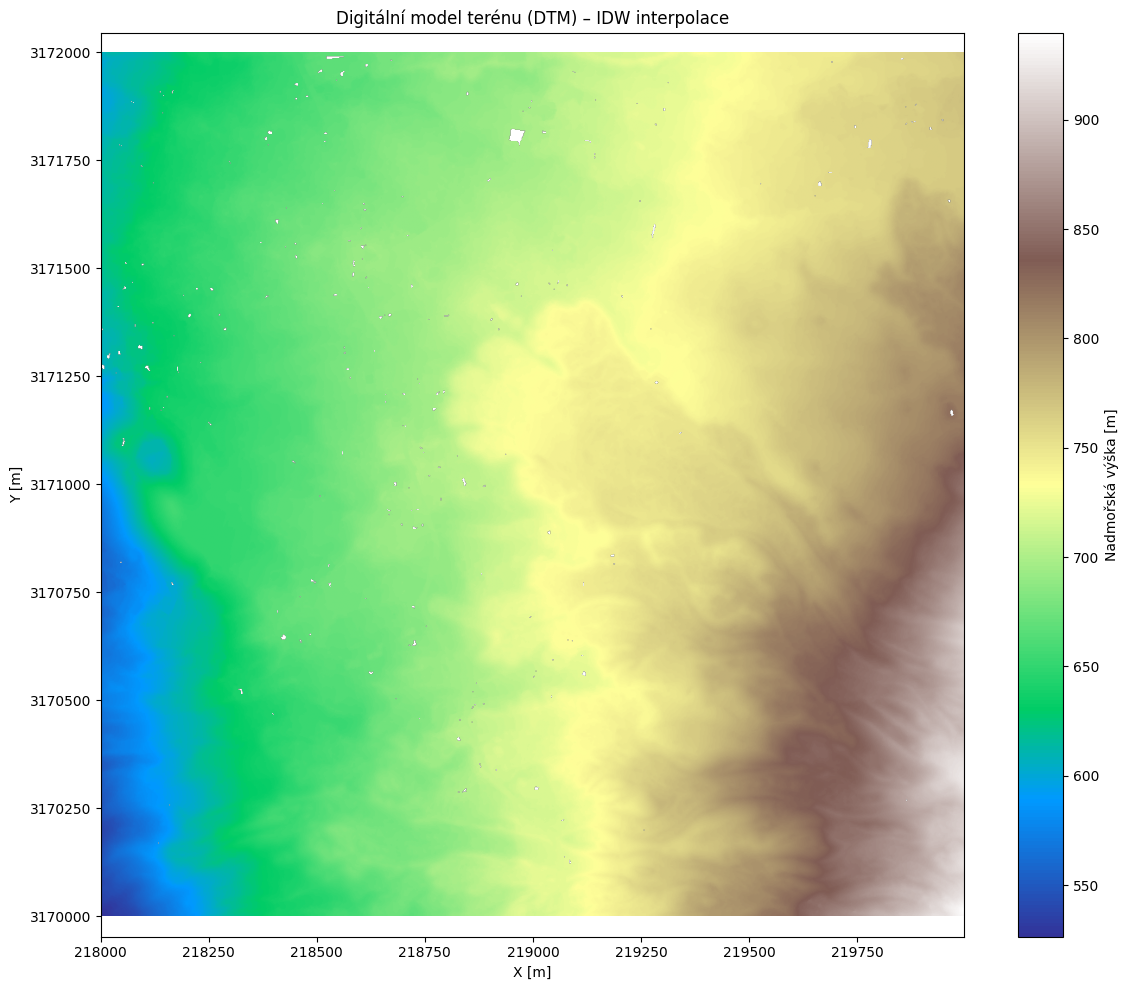

Rozměry rastru: (1000, 1000)
Počet buněk: 1000000
Minimální výška: 526.4403753446431
Maximální výška: 939.7284861323664
Počet prázdných buněk: 1269


In [6]:
# Načtení aktuální verze funkce
import idw
import importlib
importlib.reload(idw)
from idw import create_dtm

# Výběr klasifikovaných terénních bodů
ground_mask = np.asarray(data.classification) == 2

ground_x = np.asarray(data.x)[ground_mask]
ground_y = np.asarray(data.y)[ground_mask]
ground_z = np.asarray(data.z)[ground_mask]

# Interpolace a vytvoření DTM
dtm, x_grid, y_grid = create_dtm(
    ground_x,
    ground_y,
    ground_z,
    resolution=2.0,
    k=8, # Počet nejbližších sousedních bodů, které vstupují do interpolace.
    power=2, # Určuje, jak rychle klesá váha bodů se vzdáleností.
    max_distance=5.0 # Maximální vzdálenost, ze které se vyhledávají sousední body.
)

plt.figure(figsize=(12, 10))

plt.imshow(
    dtm,
    extent=[
        x_grid.min(), x_grid.max(),
        y_grid.min(), y_grid.max()
    ],
    origin="lower",
    cmap="terrain"
)

plt.colorbar(label="Nadmořská výška [m]")
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.ticklabel_format(axis="y", style="plain", useOffset=False)
plt.title("Digitální model terénu (DTM) – IDW interpolace")
plt.axis("equal")
plt.tight_layout()
plt.show()

print("Rozměry rastru:", dtm.shape)
print("Počet buněk:", dtm.size)
print("Minimální výška:", np.nanmin(dtm))
print("Maximální výška:", np.nanmax(dtm))
print("Počet prázdných buněk:", np.isnan(dtm).sum())


# Georeference rastru
transform = from_origin(
    x_grid.min(),
    y_grid.max(),
    2.0,
    2.0
)

# Uložení DTM
with rasterio.open(
    "dtm.tif",
    "w",
    driver="GTiff",
    height=dtm.shape[0],
    width=dtm.shape[1],
    count=1,
    dtype="float32",
    crs="EPSG:25828",
    transform=transform,
    nodata=np.nan
) as dst:
    dst.write(dtm.astype("float32"), 1)


**Filtrace bodů vegetace**

Pro tvorbu DSM potřebujeme vyfiltrovat vegetaci. Ta se nachází ve třech třídách:
*   3 - Nízká vegetace
*   4 - středně vysoká vegetace
*   5 - vysoká vegetace



In [7]:
# Výběr vegetačních tříd (3 = nízká, 4 = střední, 5 = vysoká vegetace)
vegetation_mask = np.isin(data.classification, [3, 4, 5])

veg_x = np.asarray(data.x)[vegetation_mask]
veg_y = np.asarray(data.y)[vegetation_mask]
veg_z = np.asarray(data.z)[vegetation_mask]

print(f"Počet bodů určené jako vegetace: {len(veg_z):,}")


# Přiřazení bodů do buněk rastru
cols = np.floor((veg_x - x_grid[0]) / 2.0).astype(int)
rows = np.floor((veg_y - y_grid[0]) / 2.0).astype(int)

# Vyřazení bodů mimo rozsah rastru
valid = (
    (cols >= 0) & (cols < dtm.shape[1]) &
    (rows >= 0) & (rows < dtm.shape[0])
)

# Identifikace buněk
cell_id = rows[valid] * dtm.shape[1] + cols[valid]

# Tabulka buněk a výšek
df = pd.DataFrame({
    "cell": cell_id,
    "z": veg_z[valid]
})

# Výpočet 95. percentilu pro každou buňku
percentiles = df.groupby("cell")["z"].quantile(0.95)

# Vytvoření výsledného rastru DSM
dsm_flat = np.full(dtm.size, np.nan)
dsm_flat[percentiles.index] = percentiles.values

dsm = dsm_flat.reshape(dtm.shape)

print("Rozměry DSM:", dsm.shape)
print("Minimální výška:", np.nanmin(dsm))
print("Maximální výška:", np.nanmax(dsm))
print("Počet buněk bez hodnoty:", np.isnan(dsm).sum())

Počet bodů určené jako vegetace: 1,717,929
Rozměry DSM: (1000, 1000)
Minimální výška: 526.741999982275
Maximální výška: 952.8110000546127
Počet buněk bez hodnoty: 337895


DSM uložíme také jako rastr se stejným rozlišením jako DTM a uložíme jako .geotiff

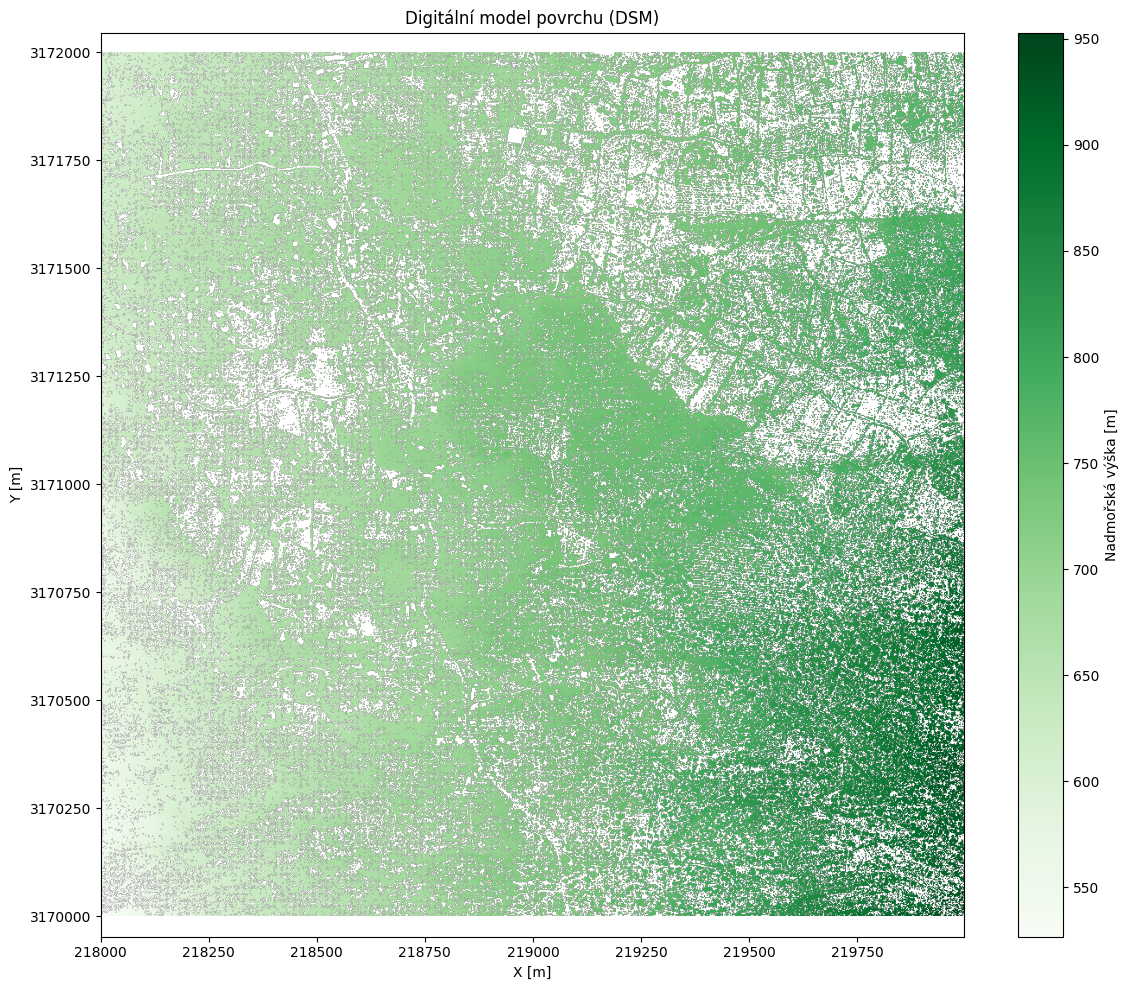

In [8]:
transform = from_origin(x_grid.min(), y_grid.max(), 2.0, 2.0)

with rasterio.open(
    "dsm.tif",
    "w",
    driver="GTiff",
    height=dsm.shape[0],
    width=dsm.shape[1],
    count=1,
    dtype="float32",
    crs="EPSG:25828",
    transform=transform,
    nodata=np.nan
) as dst:
    dst.write(dsm.astype("float32"), 1)


plt.figure(figsize=(12, 10))

plt.imshow(
    dsm,
    extent=[
        x_grid.min(), x_grid.max(),
        y_grid.min(), y_grid.max()
    ],
    origin="lower",
    cmap="Greens"
)

plt.colorbar(label="Nadmořská výška [m]")
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.ticklabel_format(axis="y", style="plain", useOffset=False)
plt.title("Digitální model povrchu (DSM)")
plt.axis("equal")
plt.tight_layout()
plt.show()

Pro lepší představu si vytvoříme 3d vizualizaci DSM

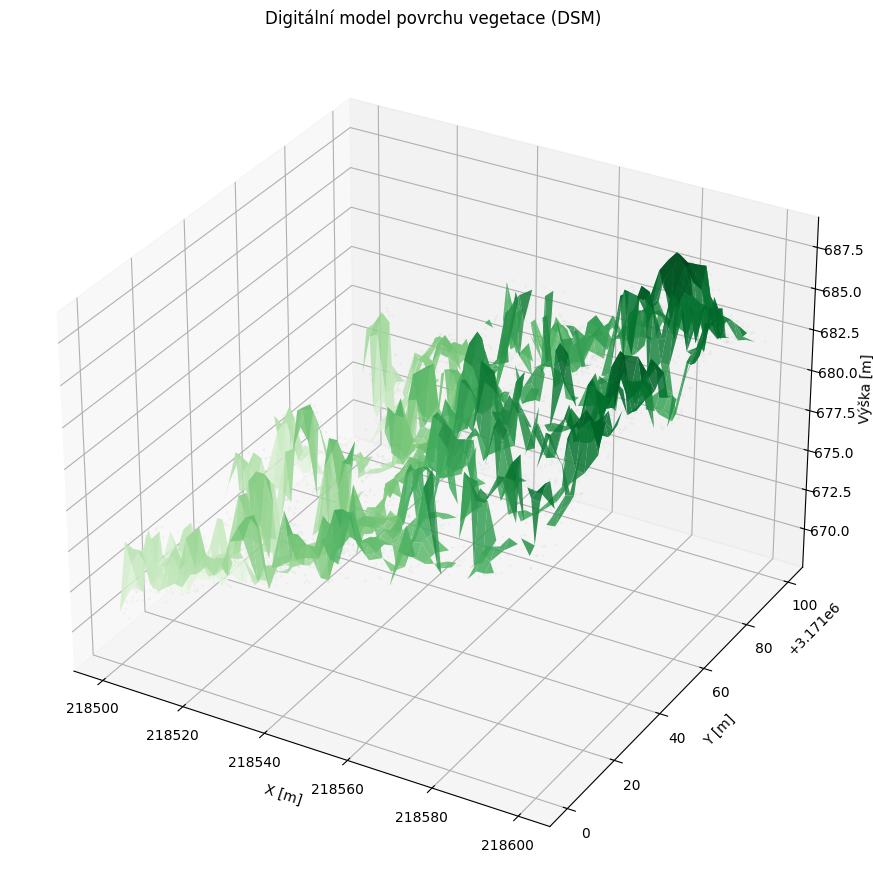

In [9]:
# Vymezení stejného výřezu
xmin, xmax = 218500, 218600
ymin, ymax = 3171000, 3171100

# Výběr buněk DSM v dané oblasti
cols = np.where((x_grid >= xmin) & (x_grid < xmax))[0]
rows = np.where((y_grid >= ymin) & (y_grid < ymax))[0]

dsm_area = dsm[np.ix_(rows, cols)]
dsm_x, dsm_y = np.meshgrid(x_grid[cols], y_grid[rows])

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

# Původní vegetační body
ax.scatter(
    veg_x[
        (veg_x >= xmin) & (veg_x < xmax) &
        (veg_y >= ymin) & (veg_y < ymax)
    ],
    veg_y[
        (veg_x >= xmin) & (veg_x < xmax) &
        (veg_y >= ymin) & (veg_y < ymax)
    ],
    veg_z[
        (veg_x >= xmin) & (veg_x < xmax) &
        (veg_y >= ymin) & (veg_y < ymax)
    ],
    c="lightgray", s=1, alpha=0.15,
    label="Vegetační body"
)

# Povrch DSM
ax.plot_surface(
    dsm_x, dsm_y, dsm_area,
    cmap="Greens",
    alpha=0.85,
    linewidth=0,
    label="DSM – 95. percentil"
)

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Výška [m]")
ax.set_title("Digitální model povrchu vegetace (DSM)")
plt.tight_layout()
plt.show()


**CHM model**

Samotný výpočet CHM je již poměrně jednoduchý. Vzniká odečtením digitálního modelu terénu (DTM) od modelu vegetačního povrchu:

```python
chm = dsm - dtm
```

Výsledkem je rastr, který vyjadřuje relativní výšku vegetace nad úrovní terénu. Každá buňka tak obsahuje informaci o výšce vegetačního pokryvu v daném místě.

Vzhledem k tomu, že model vegetačního povrchu obsahuje pouze body klasifikované jako nízká, střední a vysoká vegetace, CHM nezahrnuje výšky budov ani jiných objektů. Buňky bez vegetačních bodů zůstávají bez hodnoty (`NaN`).

Výsledný model umožňuje sledovat prostorové rozložení výšky vegetace a její variabilitu v rámci zájmového území.

Minimální výška: -2.4243881888442047
Maximální výška: 27.407976351889488
Průměrná výška: 2.6549814253194888
Počet buněk bez hodnoty: 338105


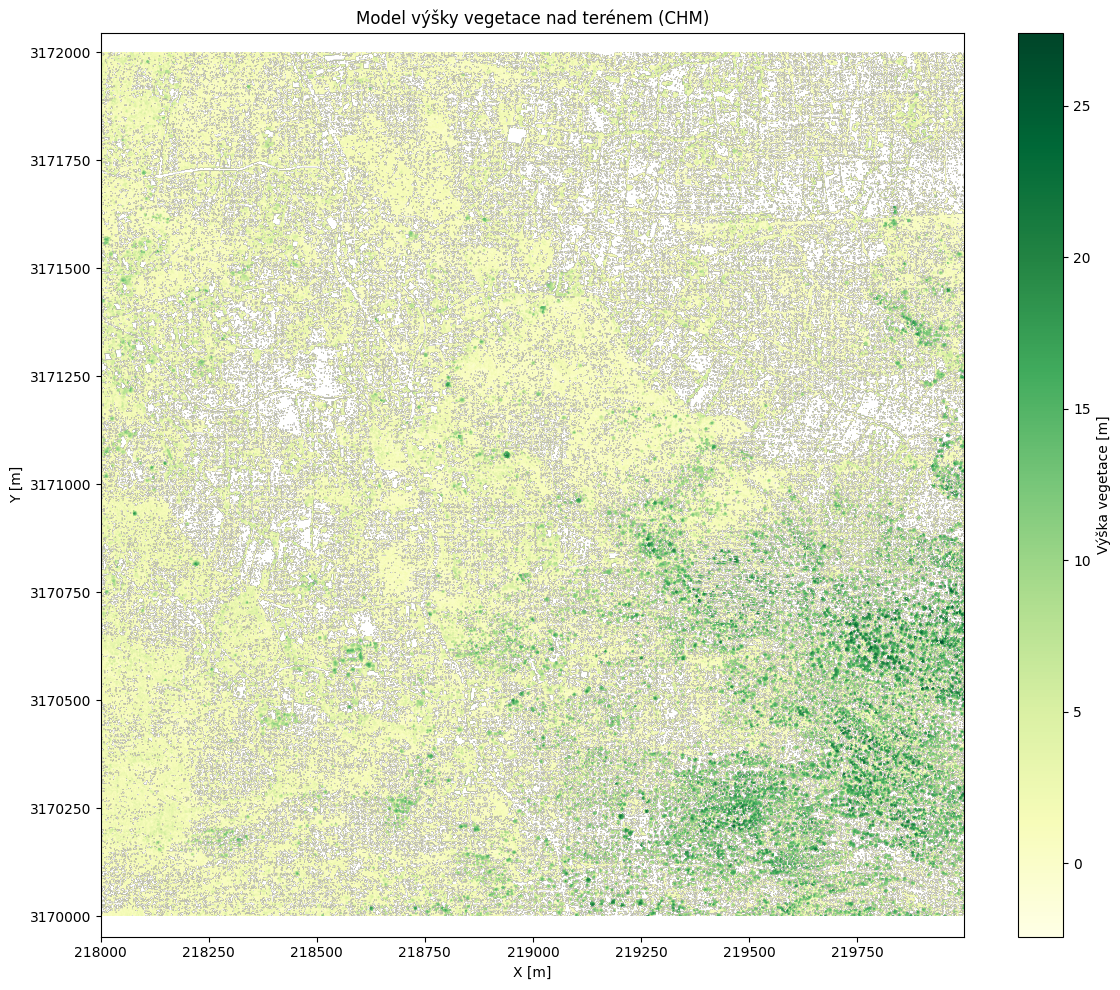

In [10]:
# Odečtení DTM od DSM
chm = dsm - dtm


print("Minimální výška:", np.nanmin(chm))
print("Maximální výška:", np.nanmax(chm))
print("Průměrná výška:", np.nanmean(chm))
print("Počet buněk bez hodnoty:", np.isnan(chm).sum())

plt.figure(figsize=(12, 10))

plt.imshow(
    chm,
    extent=[
        x_grid.min(), x_grid.max(),
        y_grid.min(), y_grid.max()
    ],
    origin="lower",
    cmap="YlGn"
)

plt.colorbar(label="Výška vegetace [m]")
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.ticklabel_format(axis="y", style="plain", useOffset=False)
plt.title("Model výšky vegetace nad terénem (CHM)")
plt.axis("equal")
plt.tight_layout()
plt.show()

with rasterio.open(
    "chm.tif",
    "w",
    driver="GTiff",
    height=chm.shape[0],
    width=chm.shape[1],
    count=1,
    dtype="float32",
    crs="EPSG:25828",
    transform=transform,
    nodata=np.nan
) as dst:
    dst.write(chm.astype("float32"), 1)

